# StreamPlus Premium-Tier Upgrade Targeting

## Predictive Modeling for Revenue Growth and Churn-Aware Campaign Targeting

### Business Scenario

StreamPlus is a fictional direct-to-consumer streaming service with roughly **4.9 million paying subscribers in North America**. It offers two subscription tiers:

- **Basic** — \$9/month, ad-supported, one-device access
- **Premium** — \$17/month, ad-free, up to four simultaneous devices, and early access to original content

The subscription-growth team is focused on increasing **ARPU (Average Revenue per User)** by converting Basic subscribers to Premium. Historically, upgrade offers sent to broad, untargeted groups of Basic subscribers have generated an approximately **11% conversion rate**.

The problem is that these campaigns also create churn risk. Internal retention analysis indicates that when a subscriber receives an upgrade offer they consider irrelevant and does not accept it, their **30-day cancellation rate increases by approximately 2.5 percentage points**. In other words, sending more offers can increase upgrade revenue, but poor targeting can simultaneously destroy customer lifetime value.

This creates a decision problem: **which Basic subscribers should receive the Premium upgrade offer?**

### Business Economics

Each targeting decision has an estimated financial consequence:

- Successful upgrade: **+\$96 in incremental annual revenue**
- Incorrectly targeted non-converter: **−\$55 in expected lifetime-value impact**
- Missed likely upgrader: foregone upgrade revenue, but no added churn exposure
- Historical untargeted campaign conversion rate: **11%**

Because the cost of an irrelevant offer is material, the objective is not simply to maximize the number of predicted upgrades or overall classification accuracy. The model must identify subscribers with sufficiently high upgrade probability while controlling false-positive targeting.

The primary business metric is:

**Net Value = (True Positives × 96) − (False Positives × 55)**

### Analytical Objective

This project builds a **logistic regression classifier** that estimates each subscriber's probability of accepting a Premium upgrade. Rather than using the default 50% classification threshold, the analysis tests multiple probability thresholds and selects the one that produces the highest expected Net Value on held-out test data.

### Project Workflow

1. Load and inspect subscriber data
2. Explore upgrade behavior and class balance
3. Prepare train and test datasets
4. Train a logistic regression classifier
5. Evaluate classification performance
6. Interpret model coefficients and odds ratios
7. Simulate targeting thresholds using business economics
8. Recommend an operational targeting rule
9. Translate results into business recommendations and limitations

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
TEST_SIZE = 0.30

REVENUE_PER_TRUE_POSITIVE = 96
COST_PER_FALSE_POSITIVE = 55

## 2. Load the Data

The dataset contains subscriber engagement and behavioral features together with the binary target variable `accepted_upgrade`.

In [2]:
DATA_URL = (
    "https://raw.githubusercontent.com/prof-tcsmith/4641s26-data/"
    "main/final-project/Project-09-StreamPlus-Upgrade/"
    "streamplus_subscribers.csv"
)

df = pd.read_csv(DATA_URL)
df.head()

,subscriber_id,months_subscribed,content_hours_per_week,devices_used,recent_search_rate,past_offer_responses,age_range_code,accepted_upgrade
0,90001,29,8.2,1,0.196,2,2,0
1,90002,29,5.6,3,0.317,3,4,1
2,90003,16,11.7,1,0.486,0,2,1
3,90004,5,5.0,4,0.259,1,3,0
4,90005,6,6.1,1,0.046,1,3,0


## 3. Data Quality and Structure

In [3]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print(f"Duplicate rows: {df.duplicated().sum():,}")
print(f"Missing values: {df.isna().sum().sum():,}")

display(df.dtypes.to_frame("dtype"))

Rows: 2,500
Columns: 8
Duplicate rows: 0
Missing values: 0


,dtype
subscriber_id,int64
months_subscribed,int64
content_hours_per_week,float64
devices_used,int64
recent_search_rate,float64
past_offer_responses,int64
age_range_code,int64
accepted_upgrade,int64


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
subscriber_id,2500.0,91250.500000,721.832160,90001.0,90625.750,91250.500,91875.25000,92500.000
months_subscribed,2500.0,14.159200,13.889702,1.0,4.000,10.000,20.00000,72.000
content_hours_per_week,2500.0,8.960080,5.167448,0.6,5.200,8.000,11.80000,44.500
devices_used,2500.0,2.234800,1.113268,1.0,1.000,2.000,3.00000,5.000
recent_search_rate,2500.0,0.197095,0.146127,0.0,0.082,0.166,0.28325,0.845
past_offer_responses,2500.0,0.802400,0.904036,0.0,0.000,1.000,1.00000,6.000
age_range_code,2500.0,2.425200,1.024121,1.0,2.000,2.000,3.00000,4.000
accepted_upgrade,2500.0,0.310800,0.462914,0.0,0.000,0.000,1.00000,1.000


### Target Class Balance

The target is moderately imbalanced: upgrade acceptances represent roughly one-third of the dataset. This means accuracy alone is not sufficient for evaluating the model.

Because the business assigns different economic consequences to successful and unsuccessful targeting decisions, the final decision threshold will be selected using **Net Value**, not the default classification threshold alone.

In [5]:
target_counts = (
    df["accepted_upgrade"]
    .value_counts()
    .rename(index={0: "No Upgrade", 1: "Accepted Upgrade"})
)

target_rates = (
    df["accepted_upgrade"]
    .value_counts(normalize=True)
    .rename(index={0: "No Upgrade", 1: "Accepted Upgrade"})
    .mul(100)
    .round(2)
)

display(
    pd.DataFrame({
        "Subscribers": target_counts,
        "Share (%)": target_rates
    })
)

,Subscribers,Share (%)
accepted_upgrade,,
No Upgrade,1723,68.92
Accepted Upgrade,777,31.08


## 4. Exploratory Data Analysis

The following features are especially relevant to the upgrade decision:

- `months_subscribed` — subscriber tenure
- `content_hours_per_week` — engagement level
- `devices_used` — breadth of platform usage
- `recent_search_rate` — recent content-search activity
- `past_offer_responses` — prior response behavior
- `age_range_code` — encoded age band

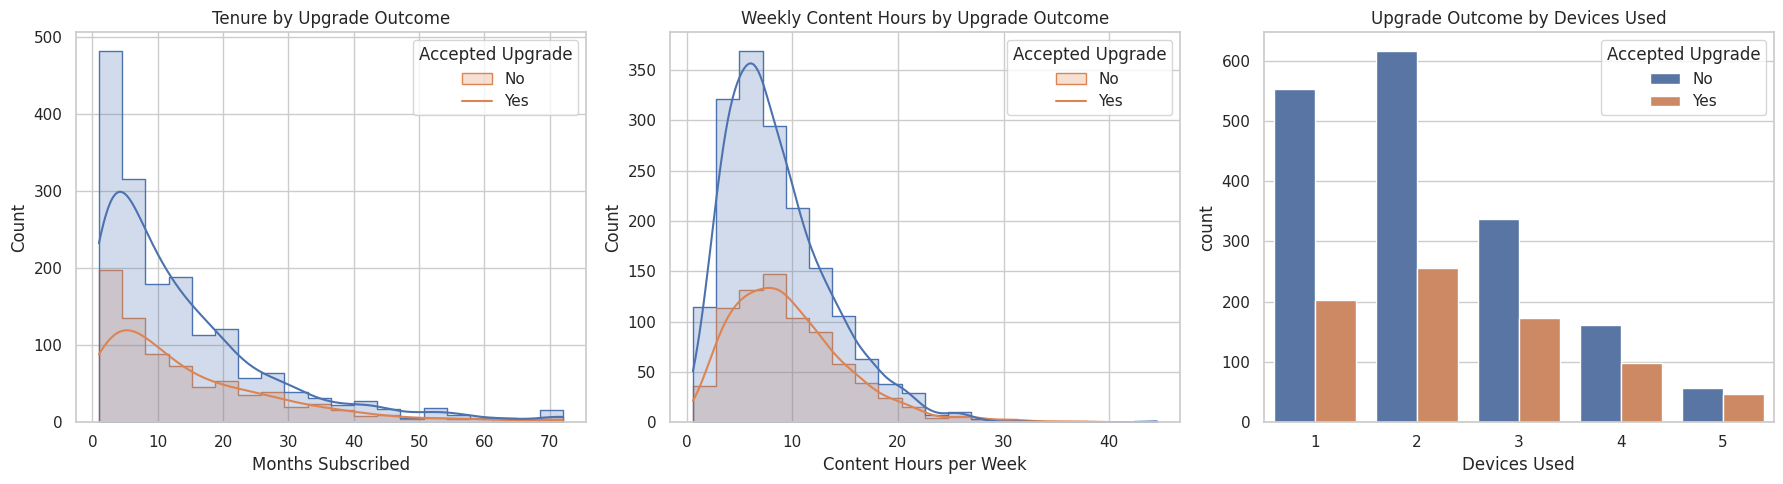

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(
    data=df,
    x="months_subscribed",
    hue="accepted_upgrade",
    bins=20,
    kde=True,
    element="step",
    ax=axes[0],
)
axes[0].set_title("Tenure by Upgrade Outcome")
axes[0].set_xlabel("Months Subscribed")

sns.histplot(
    data=df,
    x="content_hours_per_week",
    hue="accepted_upgrade",
    bins=20,
    kde=True,
    element="step",
    ax=axes[1],
)
axes[1].set_title("Weekly Content Hours by Upgrade Outcome")
axes[1].set_xlabel("Content Hours per Week")

sns.countplot(
    data=df,
    x="devices_used",
    hue="accepted_upgrade",
    ax=axes[2],
)
axes[2].set_title("Upgrade Outcome by Devices Used")
axes[2].set_xlabel("Devices Used")

for ax in axes:
    ax.legend(title="Accepted Upgrade", labels=["No", "Yes"])

plt.tight_layout()
plt.show()

### Average Behavioral Profile by Upgrade Outcome

Comparing group averages provides an intuitive view of how accepted and declined upgrades differ before fitting the model.

In [7]:
profile_columns = [
    "months_subscribed",
    "content_hours_per_week",
    "devices_used",
    "recent_search_rate",
    "past_offer_responses",
    "age_range_code",
]

profile = (
    df.groupby("accepted_upgrade")[profile_columns]
      .mean()
      .rename(index={0: "Declined", 1: "Accepted"})
      .T
)

profile["Difference (Accepted - Declined)"] = (
    profile["Accepted"] - profile["Declined"]
)

profile.round(3)

accepted_upgrade,Declined,Accepted,Difference (Accepted - Declined)
months_subscribed,13.778,15.005,1.227
content_hours_per_week,8.621,9.713,1.092
devices_used,2.161,2.399,0.238
recent_search_rate,0.177,0.242,0.066
past_offer_responses,0.674,1.088,0.414
age_range_code,2.467,2.333,-0.133


## 5. Model Preparation

`subscriber_id` is an identifier rather than a predictive feature, so it is excluded.

A stratified 70/30 train-test split preserves the class distribution in both sets. The test set is held out for unbiased model evaluation and threshold selection.

In [8]:
X = df.drop(columns=["subscriber_id", "accepted_upgrade"])
y = df["accepted_upgrade"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Training rows: {len(X_train):,}")
print(f"Test rows: {len(X_test):,}")
print(f"Training upgrade rate: {y_train.mean():.2%}")
print(f"Test upgrade rate: {y_test.mean():.2%}")

Training rows: 1,750
Test rows: 750
Training upgrade rate: 31.09%
Test upgrade rate: 31.07%


## 6. Train the Logistic Regression Model

Logistic regression is used because it provides:

- predicted upgrade probabilities,
- interpretable coefficients,
- direct odds-ratio interpretation,
- a natural foundation for threshold-based campaign targeting.

In [9]:
model = LogisticRegression(
    solver="liblinear",
    random_state=RANDOM_STATE,
    max_iter=1000,
)

model.fit(X_train, y_train)

print("Logistic regression model trained.")

Logistic regression model trained.


## 7. Model Interpretation

For logistic regression, exponentiating a coefficient produces an **odds ratio**.

- Odds ratio **> 1**: higher feature values are associated with higher upgrade odds.
- Odds ratio **< 1**: higher feature values are associated with lower upgrade odds.

**Important:** odds ratios are expressed per one-unit increase in each feature. Because the features have different units and ranges, their raw odds ratios should not be treated as directly comparable measures of feature importance.

In [10]:
odds_ratios = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": model.coef_[0],
})

odds_ratios["Odds Ratio"] = np.exp(odds_ratios["Coefficient"])
odds_ratios["Direction"] = np.where(
    odds_ratios["Odds Ratio"] >= 1,
    "Higher upgrade odds",
    "Lower upgrade odds",
)

odds_ratios.sort_values("Odds Ratio", ascending=False).reset_index(drop=True)

,Feature,Coefficient,Odds Ratio,Direction
0,recent_search_rate,2.803411,16.500841,Higher upgrade odds
1,past_offer_responses,0.491647,1.635008,Higher upgrade odds
2,devices_used,0.169998,1.185302,Higher upgrade odds
3,content_hours_per_week,0.030818,1.031298,Higher upgrade odds
4,months_subscribed,0.006531,1.006552,Higher upgrade odds
5,age_range_code,-0.173852,0.840421,Lower upgrade odds


## 8. Baseline Model Evaluation at the Default 0.50 Threshold

The default `predict()` decision threshold is 0.50. This provides a useful baseline, but it is **not assumed to be the economically optimal targeting threshold**.

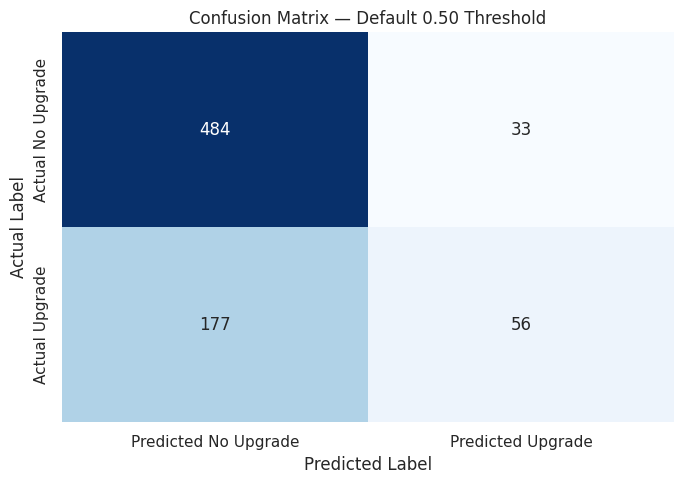

,0
Accuracy,0.720000
Precision,0.629213
Recall,0.240343
F1 Score,0.347826
True Negatives,484.000000
False Positives,33.000000
False Negatives,177.000000
True Positives,56.000000


In [11]:
y_pred_default = model.predict(X_test)

cm = confusion_matrix(y_test, y_pred_default)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Predicted No Upgrade", "Predicted Upgrade"],
    yticklabels=["Actual No Upgrade", "Actual Upgrade"],
    ax=ax,
)
ax.set_title("Confusion Matrix — Default 0.50 Threshold")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")
plt.tight_layout()
plt.show()

baseline_metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred_default),
    "Precision": precision_score(y_test, y_pred_default, zero_division=0),
    "Recall": recall_score(y_test, y_pred_default, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred_default, zero_division=0),
    "True Negatives": tn,
    "False Positives": fp,
    "False Negatives": fn,
    "True Positives": tp,
})

baseline_metrics

### Business Interpretation of the Confusion Matrix

Scikit-learn returns the binary confusion matrix in this layout:

| | Predicted No Upgrade | Predicted Upgrade |
|---|---:|---:|
| **Actual No Upgrade** | True Negative | False Positive |
| **Actual Upgrade** | False Negative | True Positive |

For StreamPlus:

- **True Positive:** correctly targeted upgrader → +\$96
- **False Positive:** targeted non-converter → −\$55 expected LTV impact
- **False Negative:** missed upgrade opportunity
- **True Negative:** correctly left untargeted

Precision is an important diagnostic because it measures how many targeted subscribers actually convert. However, the primary business objective is **Net Value**, because it explicitly combines the financial upside of true positives with the downside of false positives.

## 9. Business-Value Threshold Optimization

A probability model is more useful than a fixed binary classifier because StreamPlus can decide **how selective** the campaign should be.

For each candidate probability threshold, the campaign's estimated economic value is calculated as:

**Net Value = (True Positives × \$96) − (False Positives × \$55)**

where:

- **True Positives** are targeted subscribers who actually accept the Premium upgrade.
- **False Positives** are targeted subscribers who do not accept and are assumed to create an expected \$55 lifetime-value cost through increased churn risk.

The optimal threshold is selected **using only the held-out test set**, which reduces the risk of choosing a campaign rule that is overly tailored to the training data.

In [12]:
def evaluate_thresholds(
    y_true,
    probabilities,
    thresholds,
    revenue_per_tp=REVENUE_PER_TRUE_POSITIVE,
    cost_per_fp=COST_PER_FALSE_POSITIVE,
):
    rows = []

    for threshold in thresholds:
        y_pred = (probabilities >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

        precision = tp / (tp + fp) if (tp + fp) else 0
        recall = tp / (tp + fn) if (tp + fn) else 0
        f1 = (
            2 * precision * recall / (precision + recall)
            if (precision + recall)
            else 0
        )

        rows.append({
            "Threshold": threshold,
            "True Positives": tp,
            "False Positives": fp,
            "True Negatives": tn,
            "False Negatives": fn,
            "Contacted": tp + fp,
            "Precision": precision,
            "Recall": recall,
            "F1 Score": f1,
            "Net Value": (tp * revenue_per_tp) - (fp * cost_per_fp),
        })

    return pd.DataFrame(rows)


y_test_proba = model.predict_proba(X_test)[:, 1]
thresholds = np.arange(0.00, 1.01, 0.01)

threshold_results = evaluate_thresholds(
    y_test,
    y_test_proba,
    thresholds,
)

optimal_row = threshold_results.loc[
    threshold_results["Net Value"].idxmax()
]

threshold_results.sort_values(
    "Net Value",
    ascending=False
).head(10)

,Threshold,True Positives,False Positives,True Negatives,False Negatives,Contacted,Precision,Recall,F1 Score,Net Value
31,0.31,147,163,354,86,310,0.474194,0.630901,0.541436,5147
32,0.32,138,150,367,95,288,0.479167,0.592275,0.529750,4998
30,0.30,151,176,341,82,327,0.461774,0.648069,0.539286,4816
39,0.39,97,84,433,136,181,0.535912,0.416309,0.468599,4692
35,0.35,120,125,392,113,245,0.489796,0.515021,0.502092,4645
33,0.33,128,139,378,105,267,0.479401,0.549356,0.512000,4643
40,0.40,92,77,440,141,169,0.544379,0.394850,0.457711,4597
41,0.41,89,72,445,144,161,0.552795,0.381974,0.451777,4584
36,0.36,113,114,403,120,227,0.497797,0.484979,0.491304,4578
45,0.45,75,48,469,158,123,0.609756,0.321888,0.421348,4560


In [13]:
optimal_threshold = float(optimal_row["Threshold"])

print(f"Optimal test-set threshold: {optimal_threshold:.2f}")
print(f"Test-set Net Value: ${optimal_row['Net Value']:,.0f}")
print(f"Subscribers contacted: {int(optimal_row['Contacted']):,}")
print(f"Expected conversion rate / precision: {optimal_row['Precision']:.2%}")
print(f"Recall: {optimal_row['Recall']:.2%}")

Optimal test-set threshold: 0.31
Test-set Net Value: $5,147
Subscribers contacted: 310
Expected conversion rate / precision: 47.42%
Recall: 63.09%


### Net Value Across Probability Thresholds

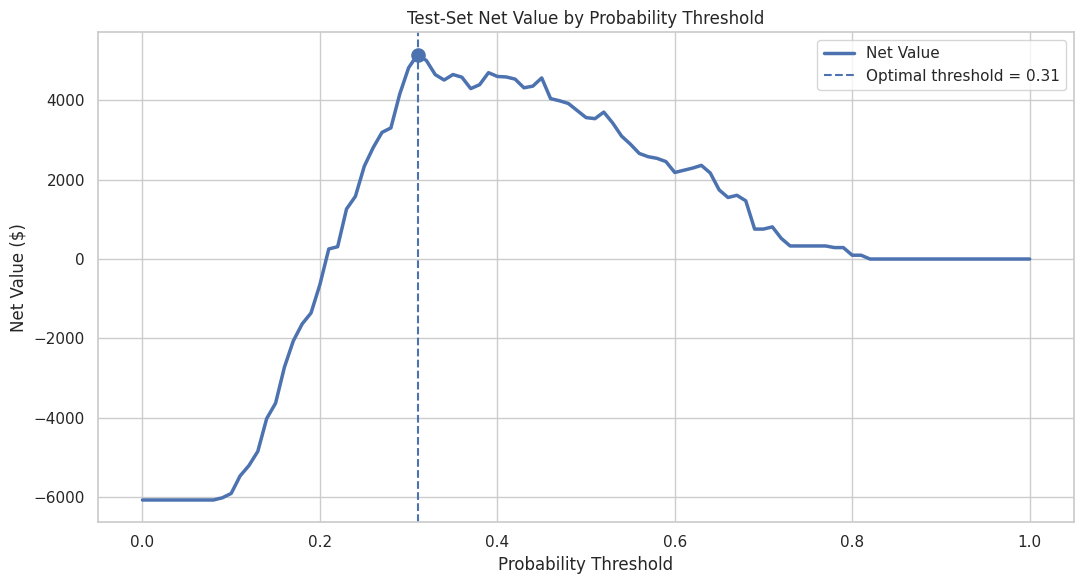

In [14]:
plt.figure(figsize=(11, 6))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Net Value"],
    linewidth=2.5,
    label="Net Value",
)

plt.axvline(
    optimal_threshold,
    linestyle="--",
    label=f"Optimal threshold = {optimal_threshold:.2f}",
)

plt.scatter(
    optimal_threshold,
    optimal_row["Net Value"],
    s=90,
    zorder=5,
)

plt.title("Test-Set Net Value by Probability Threshold")
plt.xlabel("Probability Threshold")
plt.ylabel("Net Value ($)")
plt.legend()
plt.tight_layout()
plt.show()

### Precision–Recall Trade-off

Lower thresholds contact more subscribers and generally improve recall, but they also create more false positives. Higher thresholds are more selective and generally improve precision while missing more potential upgraders.

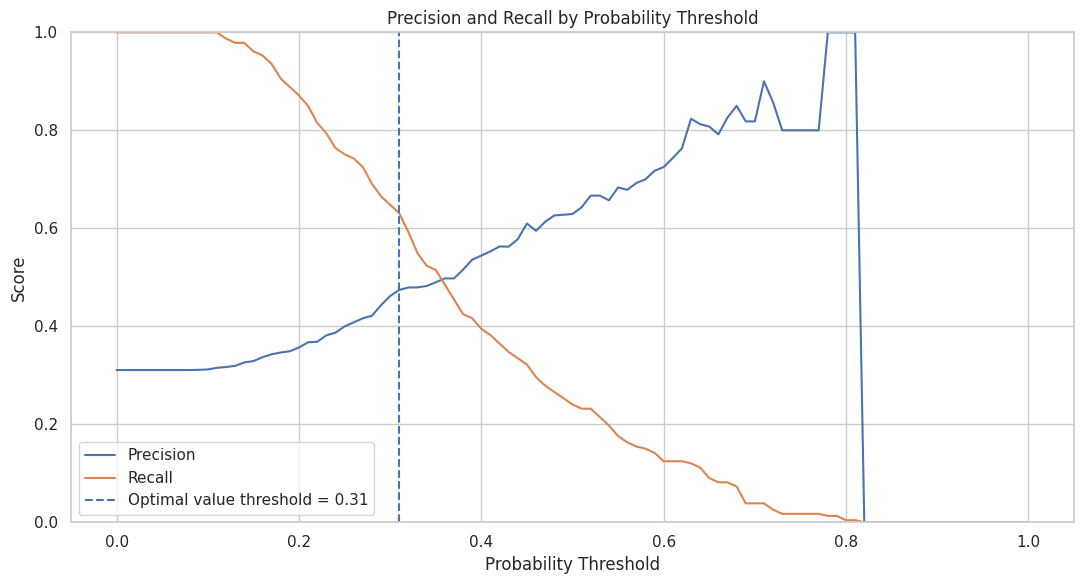

In [15]:
plt.figure(figsize=(11, 6))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    label="Precision",
)
plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    label="Recall",
)

plt.axvline(
    optimal_threshold,
    linestyle="--",
    label=f"Optimal value threshold = {optimal_threshold:.2f}",
)

plt.title("Precision and Recall by Probability Threshold")
plt.xlabel("Probability Threshold")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

## 10. Recommended Targeting Rule

**Send the Premium upgrade offer only to subscribers whose predicted probability of accepting is at least the value-maximizing threshold identified on the held-out test set.**

This rule converts the classification model into an operational campaign policy.

The recommendation is intentionally based on `predict_proba()` rather than the default `predict()` output because campaign economics determine the appropriate cutoff.

In [16]:
recommended_threshold = optimal_threshold

test_targeting_summary = pd.Series({
    "Probability Threshold": recommended_threshold,
    "Test Subscribers Contacted": int(optimal_row["Contacted"]),
    "Test Conversion Rate": optimal_row["Precision"],
    "Test Recall": optimal_row["Recall"],
    "Test Net LTV Impact": optimal_row["Net Value"],
})

test_targeting_summary

,0
Probability Threshold,0.310000
Test Subscribers Contacted,310.000000
Test Conversion Rate,0.474194
Test Recall,0.630901
Test Net LTV Impact,5147.000000


## 11. Historical Full-Dataset Simulation

The threshold chosen on the test set can also be applied retrospectively to all 2,500 historical records to understand the scale of the targeting rule.

**Caution:** the full dataset includes the records used to train the model. Therefore, these figures are an **in-sample historical simulation**, not an unbiased estimate of future campaign performance. The held-out test results above should remain the primary evidence for model generalization.

In [17]:
y_full_proba = model.predict_proba(X)[:, 1]
y_full_target = (y_full_proba >= recommended_threshold).astype(int)

tn_full, fp_full, fn_full, tp_full = confusion_matrix(
    y,
    y_full_target
).ravel()

full_contacted = tp_full + fp_full
full_precision = tp_full / full_contacted if full_contacted else 0
full_recall = tp_full / (tp_full + fn_full) if (tp_full + fn_full) else 0
full_net_value = (
    tp_full * REVENUE_PER_TRUE_POSITIVE
    - fp_full * COST_PER_FALSE_POSITIVE
)

historical_simulation = pd.Series({
    "Threshold": recommended_threshold,
    "Historical Subscribers Contacted": full_contacted,
    "Historical Conversion Rate": full_precision,
    "Historical Recall": full_recall,
    "Historical Net LTV Impact": full_net_value,
})

historical_simulation

,0
Threshold,0.310000
Historical Subscribers Contacted,1060.000000
Historical Conversion Rate,0.462264
Historical Recall,0.630631
Historical Net LTV Impact,15690.000000


## 12. Likely Upgrade Profile

The model and exploratory analysis suggest that upgrade propensity is associated with several behavioral dimensions:

- stronger engagement with the platform,
- broader device usage,
- longer subscription tenure,
- more active recent search behavior,
- stronger prior offer-response behavior.

These relationships should be treated as **associations**, not causal effects. A marketing intervention should ultimately be validated through controlled experimentation.

## 13. Business Recommendations

### 1. Replace broad upgrade campaigns with scored targeting
Score Basic subscribers with the model and target only those above the selected probability threshold.

### 2. Optimize for campaign economics, not classification accuracy
Use Net LTV Impact as the primary decision criterion. Precision, recall, and F1 remain useful diagnostics, but they do not directly encode the business cost structure.

### 3. Monitor false positives closely
False positives represent subscribers who receive an irrelevant offer and may become more likely to churn. Campaign monitoring should track both conversion and post-offer cancellation behavior.

### 4. Validate the strategy with an A/B test
Before a full rollout, compare the model-targeted campaign against the existing untargeted strategy using a controlled experiment.

### 5. Re-estimate the threshold as economics change
If upgrade revenue, churn cost, or subscriber behavior changes, the economically optimal probability threshold should be recalculated.

## 14. Limitations and Future Work

### Limitations

1. **Limited feature set** — the dataset excludes detailed content preferences, payment behavior, support interactions, and other potentially useful signals.
2. **Correlation is not causation** — the model predicts upgrade acceptance but does not prove that targeting causes an upgrade.
3. **Static historical sample** — subscriber behavior may change over time.
4. **Class imbalance** — accepted upgrades are the minority class, so accuracy can overstate practical model quality.
5. **Single-model approach** — logistic regression provides interpretability but may miss nonlinear patterns.

### Future Work

- Compare tree-based models such as Random Forest, Gradient Boosting, and XGBoost.
- Evaluate probability calibration.
- Incorporate richer subscriber engagement and content-consumption features.
- Use uplift modeling to estimate who upgrades **because of** an offer, rather than who is merely likely to upgrade.
- Run controlled A/B experiments to estimate true incremental campaign impact.
- Monitor model drift and retrain periodically.

## 15. Conclusion

This project demonstrates how a predictive model can be translated into a business decision rule.

Rather than maximizing raw classification accuracy, the analysis uses upgrade probabilities and campaign economics to determine **who should receive an offer**. The threshold-optimization framework explicitly balances incremental upgrade revenue against churn-related lifetime-value risk, producing a targeting strategy that is both analytically grounded and operationally actionable.